# Tugas 2 - CountVectorizer dan TF-IDF dengan Stop Words

**Nama:** Agus  
**NIM:** 244107020049

[Sumber modul](https://polinema.gitbook.io/jti-modul-praktikum-pembelajaran-mesin-2025-2026/js09-klasifikasi/tugas-2)

## Persiapan perbandingan

Kedua model menggunakan MultinomialNB dengan alpha=1, split stratified 80:20 seed 50, dan `stop_words="english"` karena SMS berbahasa Inggris. Pembersihan kolom mengikuti Praktikum 3, ditambah deduplikasi SMS sebelum split stratified 80:20; vocabulary/IDF di-fit hanya pada training. Penentuan fitur terbaik memakai F1 spam pada CV training; hasil test dipakai untuk evaluasi akhir.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
np.random.seed(42)
sns.set_theme(style='whitegrid')
print('Kernel:', sys.executable)

raw = pd.read_csv('data/spam.csv', encoding='latin-1')
df = raw[['v1', 'v2']].rename(columns={'v1': 'Labels', 'v2': 'SMS'}).dropna().copy()
conflicts = df.groupby('SMS')['Labels'].nunique()
conflicts = conflicts[conflicts > 1].index
df = df.loc[~df['SMS'].isin(conflicts)].drop_duplicates('SMS').reset_index(drop=True)
print('Data asli:', raw.shape, '| Teks berlabel konflik:', len(conflicts), '| Data bersih:', df.shape)
display(df['Labels'].value_counts())
df['Labels'] = df['Labels'].map({'ham': 0, 'spam': 1})
assert df['Labels'].notna().all() and not df['SMS'].duplicated().any()
X, y = df['SMS'], df['Labels']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=50, stratify=y)
assert set(X_train).isdisjoint(X_test)

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.model_selection import cross_val_score
from sklearn.metrics import precision_score, recall_score, f1_score

Kernel: /Volumes/External/miniconda3/envs/ml-praktikum/bin/python
Data asli: (5572, 5) | Teks berlabel konflik: 0 | Data bersih: (5169, 2)


Labels
ham     4516
spam     653
Name: count, dtype: int64

## Training dan evaluasi kedua representasi

CountVectorizer + stop words
              precision    recall  f1-score   support

         ham       0.98      0.99      0.99       903
        spam       0.93      0.89      0.91       131

    accuracy                           0.98      1034
   macro avg       0.96      0.94      0.95      1034
weighted avg       0.98      0.98      0.98      1034



TF-IDF + stop words
              precision    recall  f1-score   support

         ham       0.96      1.00      0.98       903
        spam       1.00      0.72      0.84       131

    accuracy                           0.96      1034
   macro avg       0.98      0.86      0.91      1034
weighted avg       0.97      0.96      0.96      1034



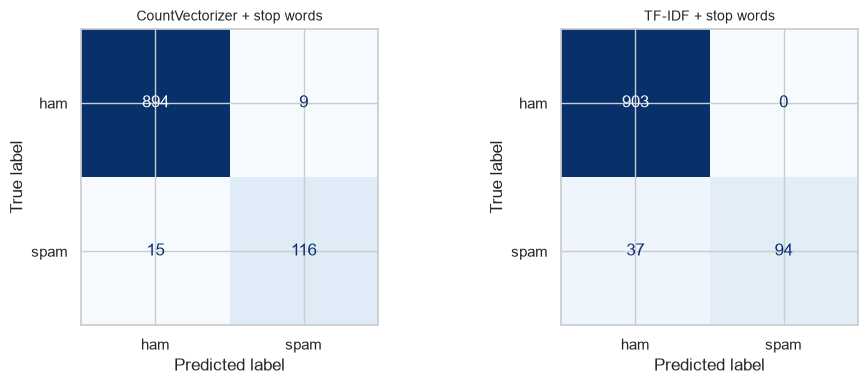

,CV F1 spam,CV std,Akurasi train,Akurasi test,Precision spam,Recall spam,F1 spam,Vocabulary
Fitur,,,,,,,,
CountVectorizer + stop words,0.9425,0.0080,0.9959,0.9768,0.928,0.8855,0.9062,7359
TF-IDF + stop words,0.8214,0.0428,0.9804,0.9642,1.000,0.7176,0.8356,7359


In [2]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
models = {
    'CountVectorizer + stop words': make_pipeline(CountVectorizer(stop_words='english'), MultinomialNB()),
    'TF-IDF + stop words': make_pipeline(TfidfVectorizer(stop_words='english'), MultinomialNB())
}
rows = []
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, model) in zip(axes, models.items()):
    cv_scores = cross_val_score(model, X_train, y_train, scoring='f1', cv=cv)
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    rows.append({'Fitur': name, 'CV F1 spam': cv_scores.mean(), 'CV std': cv_scores.std(),
                 'Akurasi train': model.score(X_train, y_train), 'Akurasi test': accuracy_score(y_test, pred),
                 'Precision spam': precision_score(y_test, pred, zero_division=0),
                 'Recall spam': recall_score(y_test, pred), 'F1 spam': f1_score(y_test, pred),
                 'Vocabulary': len(model.steps[0][1].get_feature_names_out())})
    print(name)
    print(classification_report(y_test, pred, target_names=['ham', 'spam'], zero_division=0))
    ConfusionMatrixDisplay.from_predictions(y_test, pred, ax=ax, display_labels=['ham', 'spam'],
                                           colorbar=False, cmap='Blues')
    ax.set_title(name, fontsize=10)
plt.tight_layout()
plt.show()
comparison = pd.DataFrame(rows).set_index('Fitur')
display(comparison.round(4))

## Grafik dan kesimpulan

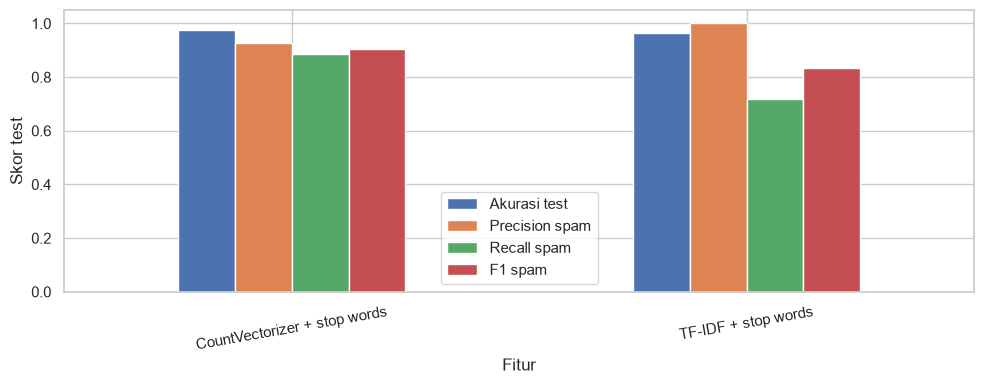

**Fitur terpilih: CountVectorizer + stop words**, berdasarkan F1 spam CV training **0.9425**; F1 spam test **0.9062**. CountVectorizer memakai frekuensi kata; TF-IDF mengurangi bobot kata yang umum. Dengan alpha yang sama, skala fitur TF-IDF dapat memberi pengaruh smoothing berbeda. Kesimpulan berlaku untuk konfigurasi ini. F1 spam diprioritaskan karena kelas ham lebih dominan.

In [3]:
comparison[['Akurasi test', 'Precision spam', 'Recall spam', 'F1 spam']].plot.bar(ylim=(0, 1.05), rot=10, figsize=(10, 4))
plt.ylabel('Skor test')
plt.tight_layout()
plt.show()
winner = comparison['CV F1 spam'].idxmax()
display(Markdown(f'**Fitur terpilih: {winner}**, berdasarkan F1 spam CV training '
                 f'**{comparison.loc[winner, "CV F1 spam"]:.4f}**; F1 spam test '
                 f'**{comparison.loc[winner, "F1 spam"]:.4f}**. '
                 'CountVectorizer memakai frekuensi kata; TF-IDF mengurangi bobot kata yang umum. '
                 'Dengan alpha yang sama, skala fitur TF-IDF dapat memberi pengaruh smoothing berbeda. '
                 'Kesimpulan berlaku untuk konfigurasi ini. F1 spam diprioritaskan karena kelas ham lebih dominan.'))